# LAB: Chaos Agent: Tools, Lore, Less Questionable Judgments

## Objective

Build a **strict complaint processor** for *NormalObjects* with LangGraph.
Every complaint follows a fixed path, so every answer can be **traced**.

```
intake → validate → investigate → resolve → close
              │
              └──(invalid)──→ reject
```

## 🗺️ Steps

| # | Step | Code |
|---|------|---|
| 1 | Setup and state definition | PROVIDED + YOUR TURN |
| 2 | Define workflow nodes | YOUR TURN |
| 3 | Build the graph | YOUR TURN |
| 4 | Test the workflow | YOUR TURN |
| 5 | Visualize the workflow path | YOUR TURN |
| 6 | Compare with LangChain | YOUR TURN |
| ✅ | `lab_proof.md` | YOUR TURN |

**Submit:** `lab_proof.md` with code, one complaint, evidence, final output, one failure.

| Label | Meaning |
|---|---|
| **PROVIDED** | Run and read it |
| **YOUR TURN** | Replace the `# TODO` lines |
| **OPTIONAL** | Not required |

**Reference:** `langgraph.ipynb`

**Prompt discipline:** use AI to review or debug, not to write your answer.

---
## Step 1: Setup and State Definition

### 1a. Install and import [PROVIDED]

Add `OPENAI_API_KEY=...` to a `.env` file next to this notebook.

In [50]:
# Install required packages (uncomment to run)
# !pip install -U langgraph langchain-openai python-dotenv

In [51]:
import os
from typing import TypedDict, List, Literal
from dotenv import load_dotenv

from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display

load_dotenv()

# Make sure OPENAI_API_KEY is set in your .env file
print("OpenAI API Key loaded:", "OPENAI_API_KEY" in os.environ)

llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

OpenAI API Key loaded: True


### 1b. Define the state [YOUR TURN]

Create `ComplaintState(TypedDict)`.

**Required fields** (used by `intake_node`):
- `complaint: str`
- `category: str`
- `workflow_path: List[str]`
- `status: str`

**Add your own:** one field per node result (validation, reason, evidence, resolution, closure).

**Hint:** `TicketState` in `langgraph.ipynb`.

In [52]:
# YOUR TURN: define the state

# TODO: class ComplaintState(TypedDict):
#           complaint: str
#           category: str
#           workflow_path: List[str]
#           status: str
#           ...

class ComplaintState(TypedDict):
    complaint: str
    category: str
    workflow_path: List[str]
    status: str
    is_valid: bool
    validation_reason: str
    evidence: str
    investigation: str
    resolution: str
    closure: str

In [53]:
# YOUR TURN: create a starting state and print it

# TODO: initial_state = {
#           "complaint": "The Downside Up portal opens at different times each day. How do I predict when?",
#           "category": "",
#           "workflow_path": [],
#           "status": "new",
#           ...
#       }

initial_state: ComplaintState = {
    "complaint": "The Downside Up portal opens at different times each day. How do I predict when?",
    "category": "",
    "workflow_path": [],
    "status": "new",
    "is_valid": False,
    "validation_reason": "",
    "evidence": "",
    "investigation": "",
    "resolution": "",
    "closure": ""  
}

print(initial_state)

# TODO: print(initial_state)

{'complaint': 'The Downside Up portal opens at different times each day. How do I predict when?', 'category': '', 'workflow_path': [], 'status': 'new', 'is_valid': False, 'validation_reason': '', 'evidence': '', 'investigation': '', 'resolution': '', 'closure': ''}


**Done when:** your starting state prints all fields.

---
## Step 2: Define Workflow Nodes [YOUR TURN]

Every node must:
1. add its name to `workflow_path`
2. print a log line, e.g. `[VALIDATE] ...`

### 2a. Lore [PROVIDED]

The source for the investigation node.

In [54]:
VALID_CATEGORIES = ["portal", "monster", "psychic", "environmental"]

LORE = {
    "portal": "Portals open when the barrier between worlds is weak. Their timing follows electrical activity, not the clock.",
    "monster": "Demogorgons act alone when hunting, but follow a hive mind when a larger entity controls them.",
    "psychic": "Psychic power drains the user's energy. Bigger or heavier objects need more energy, and nosebleeds are a warning sign.",
    "environmental": "Creatures from the Downside Up disturb electricity: lights flicker and power lines react when they are near.",
}

In [55]:
graph = StateGraph(ComplaintState)
graph.add_node


<bound method StateGraph.add_node of <langgraph.graph.state.StateGraph object at 0x000002AB88A63550>>

### 2b. Intake node [PROVIDED]

In [56]:
def intake_node(state: ComplaintState) -> ComplaintState:
    """Step 1: Intake - Parse and categorize the complaint"""
    print("\n[INTAKE] Processing complaint...")

    complaint = state["complaint"]

    # Categorize complaint using LLM
    categorization_prompt = f"""Categorize this Downside Up complaint into one of these categories:
- portal: Issues with portal timing, location, or behavior
- monster: Issues with creature behavior (demogorgons, etc.)
- psychic: Issues with psychic abilities or limitations
- environmental: Issues with electricity, weather, or physical environment
- other: Anything else

Complaint: {complaint}

Respond with ONLY the category name (portal, monster, psychic, environmental, or other)."""

    response = llm.invoke([HumanMessage(content=categorization_prompt)])
    category = response.content.strip().lower()

    # Update state
    new_state = {
        **state,
        "category": category,
        "workflow_path": state.get("workflow_path", []) + ["intake"],
        "status": "intake"
    }

    print(f"[INTAKE] Categorized as: {category}")
    return new_state

### 2c. Validation node

Valid if the category is in `VALID_CATEGORIES`. Save the result **and the reason**.

In [57]:
# YOUR TURN: validation node

# TODO: def validate_node(state: ComplaintState) -> ComplaintState:

def validation_node(state: ComplaintState) -> ComplaintState:
    """Step 2: Validation - Check if the complaint is valid"""
    print("\n[VALIDATION] Validating complaint...")

    category = state["category"]

    if category in VALID_CATEGORIES:
        is_valid = True
        validation_reason = "Complaint falls within known categories."
    else:
        is_valid = False
        validation_reason = "Complaint does not match any known categories."

    # Update state
    new_state = {
        **state,
        "is_valid": is_valid,
        "validation_reason": validation_reason,
        "workflow_path": state.get("workflow_path", []) + ["validate"],
        "status": "validated"
    }

    print(f"[VALIDATION] Valid: {is_valid}. {validation_reason}")
    return new_state

### 2d. Investigation node

Use `LORE[category]`. Ask the LLM to answer **only** from that text. Save the lore used as evidence.

In [58]:
# YOUR TURN: investigation node

# TODO: def investigate_node(state: ComplaintState) -> ComplaintState:
#           ...
def investigate_node(state: ComplaintState) -> ComplaintState:
    """Step 3: Investigation - Gather evidence and analyze the complaint"""
    print("\n[INVESTIGATION] Investigating complaint...")

    category = state["category"]
    complaint = state["complaint"]
    evidence = LORE[category]


    # Use LLM to gather evidence based on category
    investigation_prompt = f"""Answer the complaint using ONLY the lore below.
    If the lore does not contain enough information, say so.

    Complaint: {complaint}

    Lore: {evidence}

    Provide a summary of evidence and analysis relevant to this complaint."""

    response = llm.invoke([HumanMessage(content=investigation_prompt)])
    #update state

    new_state= {
        **state,
        "evidence":evidence,
        "investigation":response.content,
        "workflow_path": state.get("workflow_path",[]) + ["investigate"],
        "status":"investigated"
    }


    print(f"[INVESTIGATION] Analysis: {response.content}")
    return new_state




### 2e. Resolution node

Short fix, based **only** on the investigation.

In [59]:
# YOUR TURN: resolution node

# TODO: def resolve_node(state: ComplaintState) -> ComplaintState:
#           ...

def resolve_node(state: ComplaintState) -> ComplaintState:
    "Step 4: Resolution: - resolve the Issue"
    print("\n[RESOLUTION] Resolving the issue...")

    investigation= state["investigation"]
    question= state["complaint"]
    resolve_prompt=f""" based on this investigation:{investigation}
    resolve the issue and answer the following complaint: {question}

    Act as a friendly customer service agent. write a short, friendly response to the complaint.
    Use ONLY information supported by the investigation.
    Do not invent facts or fixes. If no fix is supported, explain the limitation.
    Keep your response to 2–3 sentences."""

    # using the llm to resolve the issue
    response =llm.invoke([HumanMessage(resolve_prompt)])

    new_state= {
        **state,
        
        "workflow_path": state.get("workflow_path",[]) + ["resolve"],
        "status":"resolved",
        "resolution":response.content
    }
    print(f"[RESOLVE] Issue resolved: {response.content}")
    return new_state

### 2f. Closure and rejection nodes

- `close_node`: closing message, status `"closed"`
- `reject_node`: rejection message with the reason, status `"rejected"`

In [60]:
# YOUR TURN: closure + rejection nodes

# TODO: def close_node(state: ComplaintState) -> ComplaintState:
#           ...

def close_node(state: ComplaintState) -> ComplaintState:
    """Finish a successfully processed complaint."""
    print("\n[CLOSE] Closing complaint...")

    closure = (
        f"Your complaint has been processed. "
        f"{state['resolution']} "
        f"This case is now closed."
    )

    new_state = {
        **state,
        "closure": closure,
        "workflow_path": state.get("workflow_path", []) + ["close"],
        "status": "closed"
    }

    print(f"[CLOSE] {closure}")
    return new_state


# TODO: def reject_node(state: ComplaintState) -> ComplaintState:
#           ...
def reject_node(state: ComplaintState) -> ComplaintState:
    """Reject a complaint that failed validation."""
    print("\n[REJECT] Rejecting complaint...")

    closure = (
        f"Your complaint could not be processed. "
        f"Reason: {state['validation_reason']}"
    )

    new_state = {
        **state,
        "closure": closure,
        "workflow_path": state.get("workflow_path", []) + ["reject"],
        "status": "rejected"
    }

    print(f"[REJECT] {closure}")
    return new_state

In [61]:
# YOUR TURN: test the nodes by hand (no graph yet)

# TODO: s = intake_node(initial_state)
# TODO: s = validate_node(s)
# TODO: ...
# TODO: print(s["workflow_path"])


s = intake_node(initial_state)
s = validation_node(s)

if s["is_valid"]:
    s = investigate_node(s)
    s = resolve_node(s)
    s = close_node(s)
else:
    s = reject_node(s)

print("\nWorkflow path:", s["workflow_path"])
print("Final status:", s["status"])
print("Final message:", s["closure"])
print(s["workflow_path"])


[INTAKE] Processing complaint...
[INTAKE] Categorized as: portal

[VALIDATION] Validating complaint...
[VALIDATION] Valid: True. Complaint falls within known categories.

[INVESTIGATION] Investigating complaint...
[INVESTIGATION] Analysis: The lore indicates that portals, including the Downside Up portal, open when the barrier between worlds is weak and that their timing is influenced by electrical activity rather than a set schedule. This means that predicting the exact opening times of the portal is not possible based on a daily clock, as the fluctuations in electrical activity can vary. Therefore, without specific information on the patterns of electrical activity, it is not feasible to predict when the portal will open each day. 

In summary, the evidence suggests that the unpredictability of the portal's opening times is inherent to its nature, as it relies on variable electrical conditions rather than a consistent timetable.

[RESOLUTION] Resolving the issue...
[RESOLVE] Issue r

**Done when:** the path prints `['intake', 'validate', 'investigate', 'resolve', 'close']`.

---
## Step 3: Build the Graph [YOUR TURN]

```
START → intake → validate ──(valid)──→ investigate → resolve → close → END
                     │
                     └──(invalid)──→ reject → END
```

**Hint:** `route_ticket` + `add_conditional_edges` in `langgraph.ipynb`.

In [62]:
# YOUR TURN: routing function

# TODO: def route_after_validation(state: ComplaintState) -> Literal["investigate", "reject"]:
#           ...
def route_after_validation(state: ComplaintState) -> Literal["investigate", "reject"]:
    """rejecets or investigates the complaint after validation"""
    
    if state["is_valid"]:
        return "investigate"
    return "reject"

#create the builder
workflow = StateGraph(ComplaintState)

#add nodes
workflow.add_node("intake", intake_node)
workflow.add_node("validate", validation_node)
workflow.add_node("investigate", investigate_node)
workflow.add_node("resolve", resolve_node)
workflow.add_node("close", close_node)
workflow.add_node("reject", reject_node)

#connect them
workflow.add_edge(START, "intake")
workflow.add_edge("intake", "validate")
workflow.add_conditional_edges(
    "validate",
    route_after_validation
)
workflow.add_edge("investigate", "resolve")
workflow.add_edge("resolve", "close")
workflow.add_edge("close", END)

workflow.add_edge("reject", END)

#make it work
app = workflow.compile()


**Done when:** `workflow.compile()` runs without errors.

---
## Step 4: Test the Workflow [YOUR TURN]

Expected: 4 `closed`, 1 `rejected`.

In [75]:
test_complaints = [
    "The Downside Up portal opens at different times each day. How do I predict when?",
    "Demogorgons sometimes work together and sometimes fight. What's their deal?",
    "El can move things with her mind but can't lift heavy rocks. Why?",
    "Why do creatures and power lines react so strangely together?",
    "This is not a valid complaint about something random"  # Should be rejected
]

print("\nTesting workflow with sample complaints...\n")

# YOUR TURN: run every complaint
results=[]
for i,complaint in enumerate(test_complaints, start=1):
    result = app.invoke({
        **initial_state,
        "complaint":complaint,
        "workflow_path": []
    })
    results.append(result)
    print(f"\n\n{'=' * 150}\nTest Nr. {i}: {result}")# TODO: results = []
# TODO: for complaint in test_complaints:
#           result = app.invoke({...})
#           results.append(result)
#           print(...)


Testing workflow with sample complaints...


[INTAKE] Processing complaint...
[INTAKE] Categorized as: portal

[VALIDATION] Validating complaint...
[VALIDATION] Valid: True. Complaint falls within known categories.

[INVESTIGATION] Investigating complaint...
[INVESTIGATION] Analysis: The lore indicates that portals, including the Downside Up portal, open based on the weakness of the barrier between worlds, which is influenced by electrical activity rather than a set schedule. This means that the timing of the portal's opening is unpredictable and varies daily. 

Summary of evidence: 
- Portals open when the barrier is weak.
- The timing is determined by electrical activity, not by the clock.

Analysis: Since the opening of the Downside Up portal is contingent upon fluctuating electrical activity, there is no reliable method to predict its opening times. The variability in electrical conditions means that one cannot establish a consistent pattern or schedule for when the portal will be

**Check:** is every claim in one resolution backed by its lore text?

---
## Step 5: Visualize the Workflow Path [YOUR TURN]

1. Draw the graph.
2. Print the path of each complaint: `intake → validate → ...`

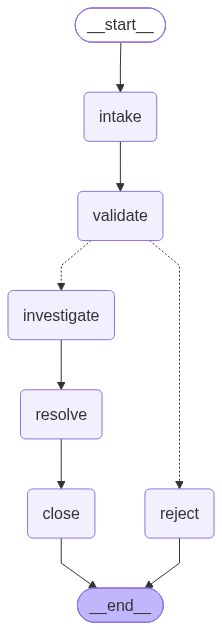

In [76]:
# YOUR TURN: draw the graph

# TODO: display(Image(app.get_graph().draw_mermaid_png()))

display(Image(app.get_graph().draw_mermaid_png()))

In [77]:
# YOUR TURN: print the path of each result

# TODO: for r in results:
#           print(" → ".join(r["workflow_path"]))
for r in results:
    print(" → ".join(r["workflow_path"]))

intake → validate → investigate → resolve → close
intake → validate → investigate → resolve → close
intake → validate → investigate → resolve → close
intake → validate → investigate → resolve → close
intake → validate → reject


---
## Step 6: Compare with LangChain [YOUR TURN]

Ask the same complaint with **one LLM call** (no graph, no lore). Then fill in the table.

In [87]:
# YOUR TURN: one LLM call

# TODO: answer = llm.invoke([HumanMessage(content=test_complaints[0])])
# TODO: print(answer.content)

# TODO: try the invalid complaint too

answer = llm.invoke([HumanMessage(content=test_complaints[0])])
print(answer.content)

To predict when the Downside Up portal opens each day, you can follow these steps:

1. **Collect Data**: Start by recording the opening times of the portal over several days. Note the date and the exact time it opens.

2. **Look for Patterns**: Analyze the data you've collected to identify any patterns. Check if the opening times follow a specific schedule, such as opening at the same time on certain days of the week or if there are any noticeable trends.

3. **Consider External Factors**: Sometimes, external factors such as events, lunar phases, or other occurrences might influence the opening times. Keep track of any such events that coincide with the portal's opening.

4. **Use Statistical Methods**: If you have enough data, you can apply statistical methods to predict future opening times. This could involve calculating averages, medians, or using more complex algorithms if you're familiar with them.

5. **Community Insights**: If there is a community or forum related to the Downsi

In [91]:
complaint = test_complaints[0]
lang_answer=app.invoke({
    **initial_state,
    "complaint": complaint,
    "workflow_path": []
})

print(lang_answer["resolution"])


[INTAKE] Processing complaint...
[INTAKE] Categorized as: portal

[VALIDATION] Validating complaint...
[VALIDATION] Valid: True. Complaint falls within known categories.

[INVESTIGATION] Investigating complaint...
[INVESTIGATION] Analysis: The lore indicates that portals, including the Downside Up portal, open when the barrier between worlds is weak and that their timing is influenced by electrical activity rather than a set schedule. This means that predicting the exact times for the portal's opening is not possible based on a daily clock, as it is contingent on fluctuating electrical conditions. 

In summary, the evidence suggests that the variability in the portal's opening times is inherent to its nature, tied to unpredictable electrical activity rather than a consistent pattern. Therefore, it is not feasible to predict when the Downside Up portal will open each day.

[RESOLUTION] Resolving the issue...
[RESOLVE] Issue resolved: Thank you for reaching out! I understand your frustr

| | LangGraph | One LLM call |
|---|---|---|
| Same answer every run? | Seems like| No |
| Invalid complaint rejected? | Yes | No |
| Path visible? | Yes | No |
| Source of each claim? | Visible trough Validation reason, evidence and investigation| No|
| Best for which client case? | Yes| No|

---
## Extensions [OPTIONAL]

- Parallel investigation
- Retry logic
- Human approval before `resolve`
- Save state with a checkpointer

In [67]:
# YOUR TURN (optional)

# TODO

---
## ✅ Write `lab_proof.md` [YOUR TURN]

```markdown
# Lab Proof: NormalObjects Complaint Processor

## 1. What I built
## 2. Query
## 3. Evidence (workflow path + log lines + lore used)
## 4. Final output
## 5. Trace (which claim comes from which lore line?)
## 6. Failure or limitation
## 7. LangGraph vs. one LLM call
```

**Before you submit:**
- [ ] No API keys or `.env`
- [ ] Only lab files
- [ ] `lab_proof.md` is the entry point

---
### Troubleshooting

| Problem | Fix |
|---|---|
| Workflow stops at a node | Check node return values and edges |
| Routing doesn't work | Routing function must return a name from the mapping |
| State not updating | Return the updated fields; keys must exist in the state |
| Valid complaint rejected | Print the raw category (dot, capital, newline?) |
| `draw_mermaid_png()` fails | Use `print(app.get_graph().draw_mermaid())` |